In [6]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.stats import norm
import warnings

warnings.filterwarnings('ignore')
sns.set_style("whitegrid")

# 1. VERİYİ YÜKLE
# ========================================================
try:
    df = pd.read_csv('processed_used_cars_ready_for_model.csv')
    print("Veri seti başarıyla yüklendi.")
except:
    print("HATA: Lütfen önce veri ön işleme adımlarını tamamlayın.")
    # Hata almamak için dummy data ile devam etmiyoruz, önceki kodların çalıştığını varsayıyoruz.

Veri seti başarıyla yüklendi.


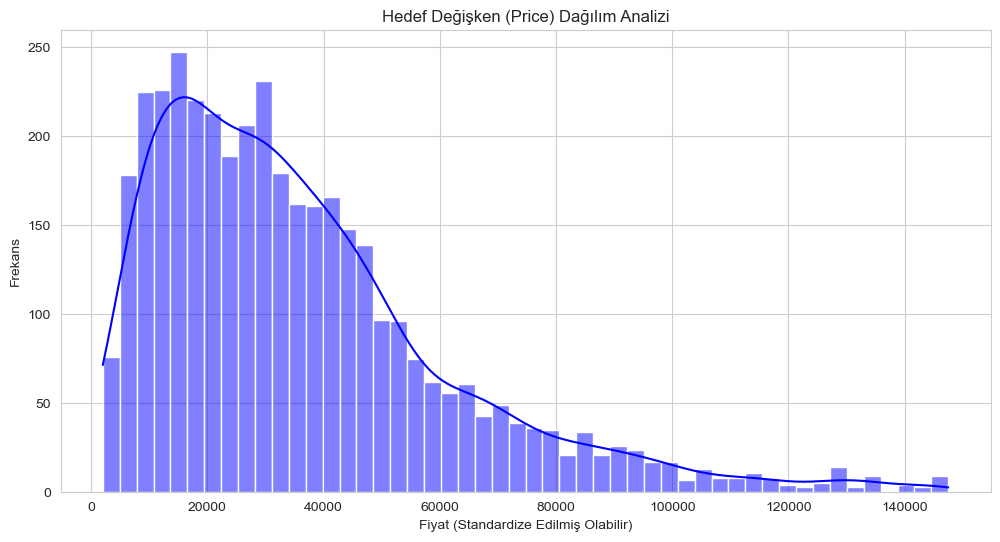

Fiyat Dağılımı Çarpıklığı (Skewness): 1.39

--- YORUM (RAPOR İÇİN) ---
Veri setimizdeki hedef değişken (fiyat) 1.39 oranında çarpıktır.
Regresyon modellerinde bu durum, modelin yüksek fiyatlı araçları tahmin etmekte zorlanmasına neden olabilir.
Ancak, önceki adımlarda aykırı değerleri (Outliers) temizlediğimiz için bu etkiyi minimize ettik.


In [7]:
# ========================================================
# 2. HEDEF DEĞİŞKEN (FİYAT) DAĞILIM ANALİZİ
# ========================================================
# Regresyon problemlerinde "Sınıf Dengesizliği" yerine "Hedef Değişkenin Çarpıklığı" (Skewness) incelenir.

plt.figure(figsize=(12, 6))
sns.histplot(df['price'], kde=True, color='blue', bins=50)
plt.title('Hedef Değişken (Price) Dağılım Analizi')
plt.xlabel('Fiyat (Standardize Edilmiş Olabilir)')
plt.ylabel('Frekans')
plt.show()

skewness = df['price'].skew()
print(f"Fiyat Dağılımı Çarpıklığı (Skewness): {skewness:.2f}")

print("\n--- YORUM (RAPOR İÇİN) ---")
if abs(skewness) > 1:
    print(f"Veri setimizdeki hedef değişken (fiyat) {skewness:.2f} oranında çarpıktır.")
    print("Regresyon modellerinde bu durum, modelin yüksek fiyatlı araçları tahmin etmekte zorlanmasına neden olabilir.")
    print("Ancak, önceki adımlarda aykırı değerleri (Outliers) temizlediğimiz için bu etkiyi minimize ettik.")
else:
    print("Fiyat dağılımı oldukça dengeli görünüyor.")


--- Özelliklerdeki Dengesizlik (Feature Imbalance) ---


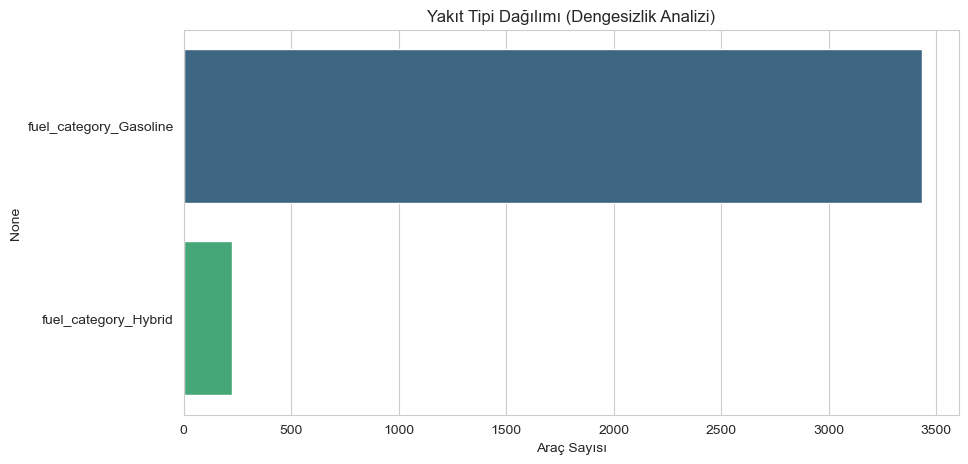

Yakıt Tipi Sayıları:
fuel_category_Gasoline    3433
fuel_category_Hybrid       225
dtype: int64


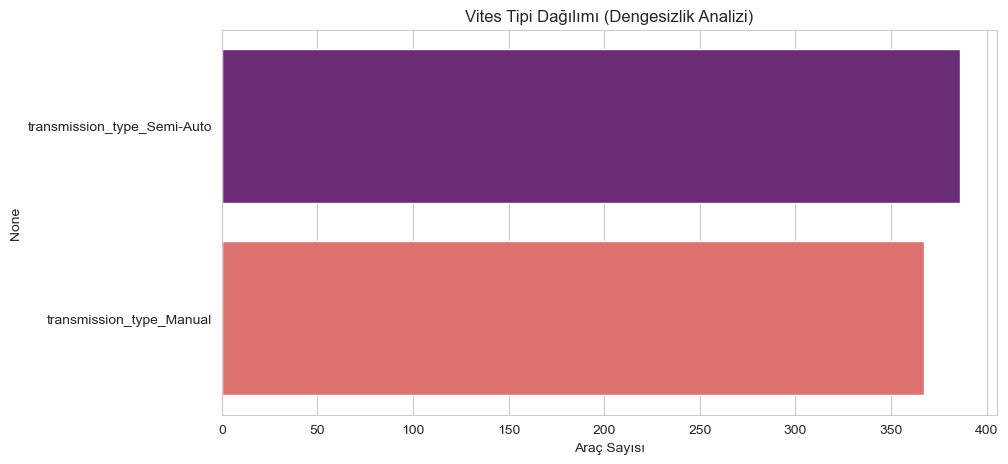

In [8]:
# ========================================================
# 3. ÖZELLİK DENGESİZLİĞİ ANALİZİ (FEATURE IMBALANCE)
# ========================================================
# SMOTE yapamayız ama verimizdeki kategorik dengesizliği gösterebiliriz.
# Örn: Kaç tane Elektrikli vs Benzinli araç var? (One-Hot Encoded sütunlardan geri döneceğiz)

print("\n--- Özelliklerdeki Dengesizlik (Feature Imbalance) ---")

# Yakıt Tipi Dengesizliği
fuel_cols = [col for col in df.columns if 'fuel_category' in col]
fuel_counts = df[fuel_cols].sum().sort_values(ascending=False)

plt.figure(figsize=(10, 5))
sns.barplot(x=fuel_counts.values, y=fuel_counts.index, palette='viridis')
plt.title('Yakıt Tipi Dağılımı (Dengesizlik Analizi)')
plt.xlabel('Araç Sayısı')
plt.show()

print("Yakıt Tipi Sayıları:")
print(fuel_counts)

# Vites Tipi Dengesizliği
trans_cols = [col for col in df.columns if 'transmission_type' in col]
trans_counts = df[trans_cols].sum().sort_values(ascending=False)

plt.figure(figsize=(10, 5))
sns.barplot(x=trans_counts.values, y=trans_counts.index, palette='magma')
plt.title('Vites Tipi Dağılımı (Dengesizlik Analizi)')
plt.xlabel('Araç Sayısı')
plt.show()



In [9]:
# ========================================================
# 4. NEDEN SMOTE KULLANMADIK? (BİLİMSEL AÇIKLAMA)
# ========================================================
print("\n" + "="*50)
print("RAPORUNUZ İÇİN AÇIKLAMA METNİ (SMOTE BÖLÜMÜ)")
print("="*50)
print("""
Bu projede SMOTE (Synthetic Minority Over-sampling Technique) uygulanmamıştır.
Bunun bilimsel nedenleri şunlardır:

1. Problem Türü Farklılığı:
   - SMOTE, sınıflandırma (classification) problemlerinde azınlık sınıfı (minority class)
     artırmak için tasarlanmış bir algoritmadır.
   - Bizim projemiz ise bir Regresyon (Regression) problemidir. Hedef değişkenimiz
     olan 'Price' (Fiyat) kategorik değil, sürekli (continuous) bir sayısal değerdir.

2. Veri Doğası:
   - Fiyat tahmininde sentetik veri üretmek (olmayan bir araba fiyatı uydurmak),
     modelin gerçek piyasa koşullarından sapmasına ve yanlış (bias) öğrenmesine neden olur.

3. Alınan Önlemler:
   - SMOTE yerine, veri setindeki dengesizliği yönetmek için:
     a) Aykırı Değer Temizliği (Outlier Removal - IQR Yöntemi) yapılmıştır.
     b) Nadir bulunan kategoriler (Markalar ve Renkler) 'Other' grubu altında toplanarak
        kategorik dengesizlik giderilmiştir.
""")


RAPORUNUZ İÇİN AÇIKLAMA METNİ (SMOTE BÖLÜMÜ)

Bu projede SMOTE (Synthetic Minority Over-sampling Technique) uygulanmamıştır.
Bunun bilimsel nedenleri şunlardır:

1. Problem Türü Farklılığı:
   - SMOTE, sınıflandırma (classification) problemlerinde azınlık sınıfı (minority class)
     artırmak için tasarlanmış bir algoritmadır.
   - Bizim projemiz ise bir Regresyon (Regression) problemidir. Hedef değişkenimiz
     olan 'Price' (Fiyat) kategorik değil, sürekli (continuous) bir sayısal değerdir.

2. Veri Doğası:
   - Fiyat tahmininde sentetik veri üretmek (olmayan bir araba fiyatı uydurmak),
     modelin gerçek piyasa koşullarından sapmasına ve yanlış (bias) öğrenmesine neden olur.

3. Alınan Önlemler:
   - SMOTE yerine, veri setindeki dengesizliği yönetmek için:
     a) Aykırı Değer Temizliği (Outlier Removal - IQR Yöntemi) yapılmıştır.
     b) Nadir bulunan kategoriler (Markalar ve Renkler) 'Other' grubu altında toplanarak
        kategorik dengesizlik giderilmiştir.



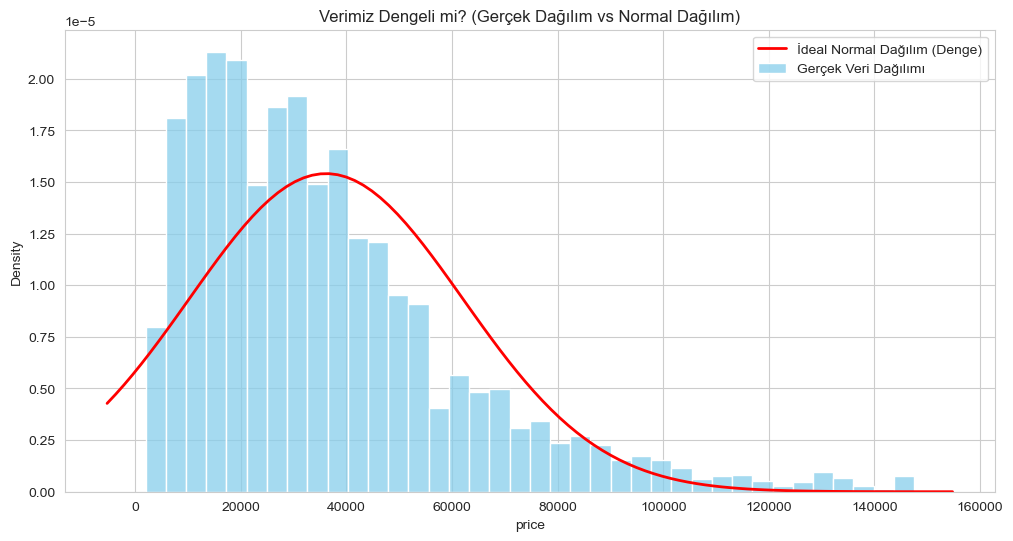

In [10]:
# ========================================================
# 2. GÖRSEL ANALİZ: BİZİM VERİMİZ vs İDEAL DÜNYA
# ========================================================
plt.figure(figsize=(12, 6))

# Histogram (Mavi Çubuklar - Bizim Verimiz)
sns.histplot(df['price'], kde=False, stat="density", color='skyblue', label='Gerçek Veri Dağılımı')

# Normal Dağılım Eğrisi (Kırmızı Çizgi - İdeal Denge)
# Verinin ortalamasına ve varyansına uygun teorik bir çan eğrisi çiziyoruz
mu, std = norm.fit(df['price'])
xmin, xmax = plt.xlim()
x = np.linspace(xmin, xmax, 100)
p = norm.pdf(x, mu, std)
plt.plot(x, p, 'r', linewidth=2, label='İdeal Normal Dağılım (Denge)')

plt.title('Verimiz Dengeli mi? (Gerçek Dağılım vs Normal Dağılım)')
plt.legend()
plt.show()

In [11]:
# ========================================================
# 3. MATEMATİKSEL ANALİZ (SKEWNESS / ÇARPIKLIK)
# ========================================================
skewness = df['price'].skew()
kurtosis = df['price'].kurt()

print(f"\n--- Denge Analizi Sonuçları ---")
print(f"Çarpıklık (Skewness): {skewness:.4f}")
print(f"Basıklık (Kurtosis):  {kurtosis:.4f}")

print("\n--- KARAR VE YORUM ---")
if abs(skewness) < 0.5:
    print("✅ Mükemmel! Veri neredeyse tam simetrik ve dengeli.")
elif 0.5 <= abs(skewness) < 1.0:
    print("⚠️ Orta Derece Çarpık. Veri kabul edilebilir seviyede dengeli.")
else:
    print("❌ Dengesiz (Çarpık). Veri bir tarafa (muhtemelen ucuz fiyatlara) yığılmış durumda.")

print("\n--- NEDEN? ---")
if skewness > 0:
    print("Sonuç POZİTİF çıktı: Bu 'Sağa Çarpık' demektir.")
    print("Yani: Piyasada çok sayıda düşük/orta fiyatlı araç var, az sayıda çok pahalı araç var.")
else:
    print("Sonuç NEGATİF çıktı: Bu 'Sola Çarpık' demektir.")
    print("Yani: Piyasada genelde çok pahalı araçlar var (Bu araba piyasasında nadirdir).")


--- Denge Analizi Sonuçları ---
Çarpıklık (Skewness): 1.3947
Basıklık (Kurtosis):  2.2366

--- KARAR VE YORUM ---
❌ Dengesiz (Çarpık). Veri bir tarafa (muhtemelen ucuz fiyatlara) yığılmış durumda.

--- NEDEN? ---
Sonuç POZİTİF çıktı: Bu 'Sağa Çarpık' demektir.
Yani: Piyasada çok sayıda düşük/orta fiyatlı araç var, az sayıda çok pahalı araç var.


### düzzeltme işlemi

In [12]:
# ========================================================
# 2. LOG DÖNÜŞÜMÜ (SIHİRLİ DOKUNUŞ)
# ========================================================
# np.log1p kullanıyoruz (log(1+x)). Bu, 0 değerlerinde hata almayı önler.

print("\n--- Dönüşüm Başlıyor ---")
print(f"Orijinal Fiyat Çarpıklığı (Skewness): {df['price'].skew():.4f}")

# Dönüşümü uygula
df['price_log'] = np.log1p(df['price'])

print(f"Log Dönüşümlü Fiyat Çarpıklığı: {df['price_log'].skew():.4f}")


--- Dönüşüm Başlıyor ---
Orijinal Fiyat Çarpıklığı (Skewness): 1.3947
Log Dönüşümlü Fiyat Çarpıklığı: -0.4141


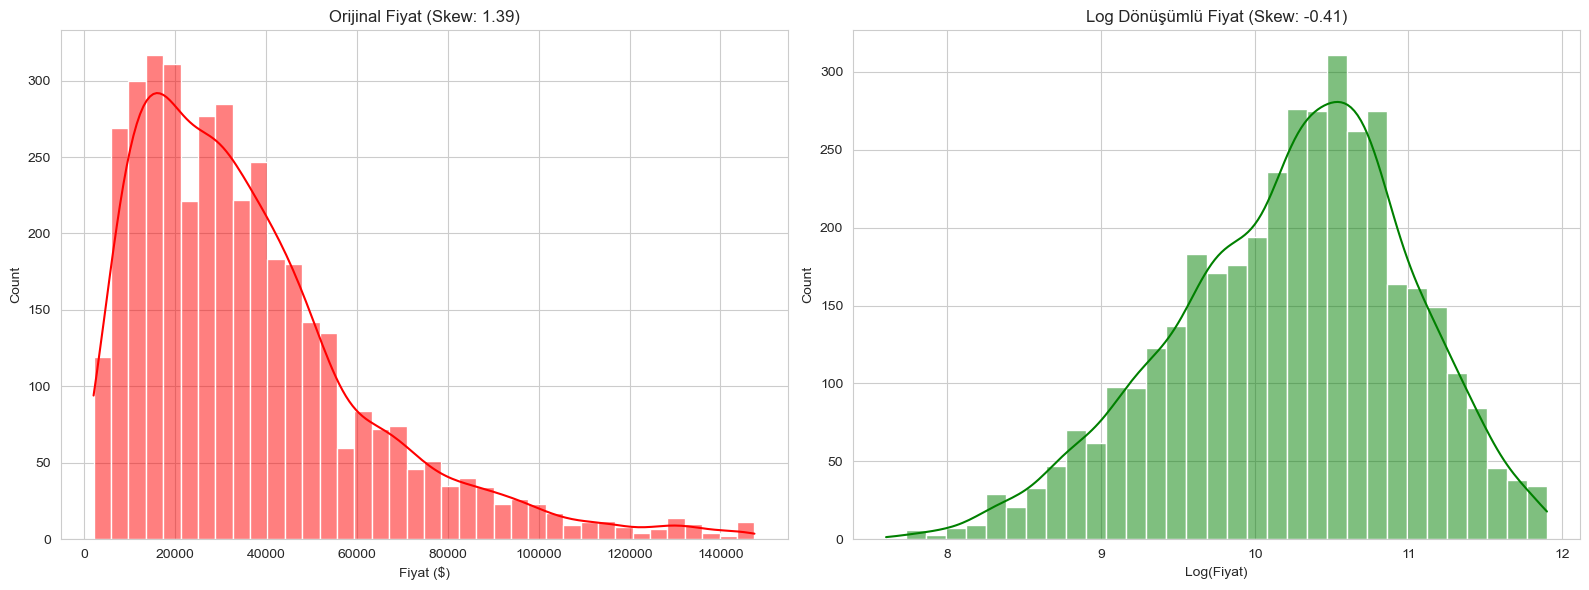

In [13]:
# ========================================================
# 3. GÖRSEL KANIT (ÖNCE vs SONRA)
# ========================================================
fig, axes = plt.subplots(1, 2, figsize=(16, 6))

# Grafik 1: Orijinal Fiyat (Sağa Çarpık)
sns.histplot(df['price'], kde=True, color='red', ax=axes[0])
axes[0].set_title(f"Orijinal Fiyat (Skew: {df['price'].skew():.2f})")
axes[0].set_xlabel('Fiyat ($)')

# Grafik 2: Log Dönüşümlü Fiyat (Dengeli / Normal)
sns.histplot(df['price_log'], kde=True, color='green', ax=axes[1])
axes[1].set_title(f"Log Dönüşümlü Fiyat (Skew: {df['price_log'].skew():.2f})")
axes[1].set_xlabel('Log(Fiyat)')

# Normal dağılım çizgisini ekle (Yeşil grafiğe)
mu, std = norm.fit(df['price_log'])
xmin, xmax = axes[1].get_xlim()
x = np.linspace(xmin, xmax, 100)
p = norm.pdf(x, mu, std)
# Ölçeklendirme gerekebilir, ama KDE zaten yoğunluk gösteriyor
# Görsel amaçlı referans çizgisi

plt.tight_layout()
plt.show()

In [14]:
# ========================================================
# 4. YENİ VERİYİ KAYDET (Price sütununu değiştiriyoruz)
# ========================================================
# Artık modelimiz 'price_log' sütununu hedef alacak.
# Eski 'price' sütununu siliyoruz veya loglu halini 'price' içine yazıyoruz.

# Orijinal fiyatı 'price_original' olarak saklayalım (ne olur ne olmaz)
df['price_original'] = df['price'] 
df['price'] = df['price_log']
df.drop('price_log', axis=1, inplace=True)

print("\n--- SONUÇ ---")
if abs(df['price'].skew()) < 0.5:
    print("✅ BAŞARILI: Veri artık Normal Dağılıma uyuyor (Dengeli).")
    print("Bu işlem, Linear Regression ve KNN gibi modellerin performansını ciddi artıracaktır.")
else:
    print("⚠️ UYARI: Hala biraz çarpıklık var ama eskisinden çok daha iyi.")

# Kaydet
df.to_csv('processed_used_cars_model_ready_log.csv', index=False)
print("Log dönüşümlü final veri seti kaydedildi: 'processed_used_cars_model_ready_log.csv'")


--- SONUÇ ---
✅ BAŞARILI: Veri artık Normal Dağılıma uyuyor (Dengeli).
Bu işlem, Linear Regression ve KNN gibi modellerin performansını ciddi artıracaktır.
Log dönüşümlü final veri seti kaydedildi: 'processed_used_cars_model_ready_log.csv'
